In [17]:
pip install requests beautifulsoup4 pandas matplotlib

In [18]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import urljoin

BASE_URL = "https://books.toscrape.com/"
HEADERS = {"User-Agent": "Mozilla/5.0"}
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def get_soup(url):
    """Download a webpage and parse its HTML."""
    response = requests.get(url, headers=HEADERS, timeout=20)
    response.raise_for_status()
    return BeautifulSoup(response.text, "html.parser")


def scrape_books_from_page(soup, page_url):
    """Extract book title, price, rating, availability and URL from one page."""
    records = []

    for book in soup.select("article.product_pod"):
        title_element = book.select_one("h3 a")
        price_element = book.select_one("p.price_color")
        rating_element = book.select_one("p.star-rating")
        availability_element = book.select_one("p.instock.availability")

        if not all([title_element, price_element, rating_element, availability_element]):
            continue

        title = title_element.get("title", title_element.get_text(strip=True))
        price_text = price_element.get_text(strip=True).replace("£", "").replace("Â", "")
        rating_classes = rating_element.get("class", [])
        rating_word = next((word for word in rating_classes if word in RATING_MAP), None)
        availability_text = availability_element.get_text(" ", strip=True)
        availability = "In stock" if "In stock" in availability_text else "Out of stock"
        book_url = urljoin(page_url, title_element.get("href", ""))

        records.append({
            "Title": title,
            "Price": float(price_text),
            "Rating": RATING_MAP.get(rating_word),
            "Availability": availability,
            "URL": book_url
        })

    return records

Mission 1: Reconnaissance



| Data Needed  | HTML Tag / Class Found   | Your Notes                                                                                                       |
| ------------ | ------------------------ | ---------------------------------------------------------------------------------------------------------------- |
| Book Title   | `h3 a`                   | The full book title is stored in the `title` attribute of the anchor (`<a>`) tag. Example: A Light in the Attic. |
| Price        | `p.price_color`          | The price is displayed in pounds (£). Example: £51.77.                                                           |
| Rating       | `p.star-rating`          | The rating is stored as a CSS class, such as `Three`, which represents 3 stars. Ratings range from One to Five.  |
| Availability | `p.instock.availability` | This class displays the book's stock status. Example: In stock.                                                  |





Mission 2:  Capture the Data

In [19]:
print("\n" + "=" * 68)
print("MISSION 2 — CAPTURE THE DATA: FIRST PAGE")
print("=" * 68)

first_page_soup = get_soup(BASE_URL)
first_page_records = scrape_books_from_page(first_page_soup, BASE_URL)
first_page_df = pd.DataFrame(
    first_page_records,
    columns=["Title", "Price", "Rating", "Availability", "URL"]
)

print(f"Number of books scraped from page 1: {len(first_page_df)}")
print("\nFirst-page data (first 5 rows):")
print(first_page_df.head().to_string(index=False))
print("\nColumn names:")
print(list(first_page_df.columns))
print("\nData types:")
print(first_page_df.dtypes.to_string())
print("\nMISSION 2 COMPLETE.")


MISSION 2 — CAPTURE THE DATA: FIRST PAGE
Number of books scraped from page 1: 20

First-page data (first 5 rows):
                                Title  Price  Rating Availability                                                                                      URL
                 A Light in the Attic  51.77       3     In stock                https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html
                   Tipping the Velvet  53.74       1     In stock                   https://books.toscrape.com/catalogue/tipping-the-velvet_999/index.html
                           Soumission  50.10       1     In stock                           https://books.toscrape.com/catalogue/soumission_998/index.html
                        Sharp Objects  47.82       4     In stock                        https://books.toscrape.com/catalogue/sharp-objects_997/index.html
Sapiens: A Brief History of Humankind  54.23       5     In stock https://books.toscrape.com/catalogue/sapiens

Mission 3: Scale the operation

In [20]:
print("\n" + "=" * 68)
print("MISSION 3 — MULTI-PAGE SCRAPING AND CSV")
print("=" * 68)

PAGES_TO_SCRAPE = 5
all_records = []

for page_number in range(1, PAGES_TO_SCRAPE + 1):
    if page_number == 1:
        page_url = BASE_URL
        soup = first_page_soup
    else:
        page_url = urljoin(BASE_URL, f"catalogue/page-{page_number}.html")
        soup = get_soup(page_url)

    page_records = scrape_books_from_page(soup, page_url)
    all_records.extend(page_records)
    print(f"Page {page_number}: {len(page_records)} books scraped")

books_df = pd.DataFrame(
    all_records,
    columns=["Title", "Price", "Rating", "Availability", "URL"]
)

# Clean data and confirm appropriate types.
books_df["Title"] = books_df["Title"].astype(str).str.strip()
books_df["Price"] = pd.to_numeric(books_df["Price"], errors="coerce")
books_df["Rating"] = pd.to_numeric(books_df["Rating"], errors="coerce")
books_df["Availability"] = books_df["Availability"].astype(str).str.strip()
books_df["URL"] = books_df["URL"].astype(str).str.strip()
books_df = books_df.dropna(subset=["Title", "Price", "Rating"])
books_df = books_df.drop_duplicates(subset=["Title"]).reset_index(drop=True)
books_df["Rating"] = books_df["Rating"].astype(int)

csv_file = "competitor_books.csv"
books_df.to_csv(csv_file, index=False)

print(f"\nTotal books in cleaned dataset: {len(books_df)}")
print("\nDataFrame preview (first 10 rows):")
print(books_df.head(10).to_string(index=False))
print("\nDataset columns:")
print(list(books_df.columns))
print(f"\nCSV created: {csv_file}")
print("\nMISSION 3 COMPLETE.")


MISSION 3 — MULTI-PAGE SCRAPING AND CSV
Page 1: 20 books scraped
Page 2: 20 books scraped
Page 3: 20 books scraped
Page 4: 20 books scraped
Page 5: 20 books scraped

Total books in cleaned dataset: 100

DataFrame preview (first 10 rows):
                                                                                         Title  Price  Rating Availability                                                                                                                                               URL
                                                                          A Light in the Attic  51.77       3     In stock                                                                         https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html
                                                                            Tipping the Velvet  53.74       1     In stock                                                                            https://books.toscrape.co

Mission 4: Answer business questions


MISSION 4 — INTELLIGENCE ANALYSIS
Q1. Which scraped book is the most expensive?
Answer: The Death of Humanity: and the Case for Life — £58.11

Q2. Which scraped book is the cheapest?
Answer: Patience — £10.16

Q3. What is the average book price?
Answer: £34.56

Q4. How many books have a 5-star rating?
Answer: 19 out of 100 books

Q5. What percentage of the scraped books are in stock?
Answer: 100.00% (100 out of 100 books)

Q6. What are the Top 5 highest-rated books?
                                                                            Title  Price  Rating Availability
                                 Princess Between Worlds (Wide-Awake Princess #5)  13.34       5     In stock
Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1)  13.61       5     In stock
                                                                   Sophie's World  15.94       5     In stock
                                                                           Thirst  17.27

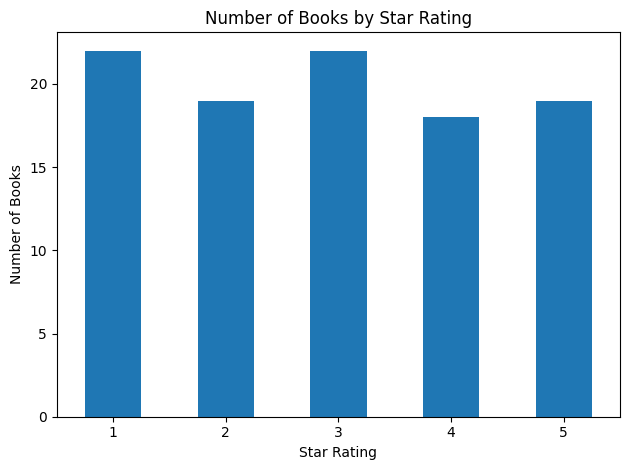


MISSION 4 COMPLETE.


In [21]:
print("\n" + "=" * 68)
print("MISSION 4 — INTELLIGENCE ANALYSIS")
print("=" * 68)

if books_df.empty:
    raise RuntimeError("No book data was scraped. Check your internet connection or website.")

most_expensive = books_df.loc[books_df["Price"].idxmax()]
cheapest = books_df.loc[books_df["Price"].idxmin()]
average_price = books_df["Price"].mean()
five_star_books = books_df[books_df["Rating"] == 5]
in_stock_count = (books_df["Availability"] == "In stock").sum()
in_stock_percent = in_stock_count / len(books_df) * 100
top_five = books_df.sort_values(
    ["Rating", "Price"], ascending=[False, True]
).head(5)

print("Q1. Which scraped book is the most expensive?")
print(f"Answer: {most_expensive['Title']} — £{most_expensive['Price']:.2f}")

print("\nQ2. Which scraped book is the cheapest?")
print(f"Answer: {cheapest['Title']} — £{cheapest['Price']:.2f}")

print("\nQ3. What is the average book price?")
print(f"Answer: £{average_price:.2f}")

print("\nQ4. How many books have a 5-star rating?")
print(f"Answer: {len(five_star_books)} out of {len(books_df)} books")

print("\nQ5. What percentage of the scraped books are in stock?")
print(f"Answer: {in_stock_percent:.2f}% ({in_stock_count} out of {len(books_df)} books)")

print("\nQ6. What are the Top 5 highest-rated books?")
print(top_five[["Title", "Price", "Rating", "Availability"]].to_string(index=False))

print("\nQ7. Among the 5-star books, which one is the cheapest?")
if len(five_star_books) > 0:
    cheapest_five_star = five_star_books.loc[five_star_books["Price"].idxmin()]
    print(f"Answer: {cheapest_five_star['Title']} — £{cheapest_five_star['Price']:.2f}")
else:
    print("Answer: No 5-star books were found in the scraped dataset.")

print("\nBONUS 3 — NUMBER OF BOOKS AT EACH STAR-RATING LEVEL")
rating_counts = books_df["Rating"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
for rating, count in rating_counts.items():
    print(f"{rating} star(s): {count} book(s)")

print("\nBONUS 4 — BAR CHART OF RATING COUNTS")
rating_counts.plot(kind="bar", rot=0)
plt.title("Number of Books by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.savefig("rating_counts.png", dpi=150)
print("Bar chart saved as: rating_counts.png")
plt.show()

print("\nMISSION 4 COMPLETE.")

Mission 5: Business decision

In [22]:
print("\n" + "=" * 68)
print("MISSION 5 — BUSINESS DECISION AND RECOMMENDATION")
print("=" * 68)

print("Evidence from the scraped data:")
print(f"1. {len(five_star_books)} out of {len(books_df)} books have a 5-star rating.")
print(f"2. The average listed price is £{average_price:.2f}.")
print(f"3. {in_stock_percent:.2f}% of the scraped books are listed as in stock.")

recommended_books = books_df.sort_values(
    ["Rating", "Price"], ascending=[False, True]
).head(3)

print("\nBooks to consider prioritizing (high rating, lower price used as tie-breaker):")
print(recommended_books[["Title", "Price", "Rating"]].to_string(index=False))

recommended_titles = ", ".join(recommended_books["Title"].tolist())
print("\nSuggested business recommendation:")
print(
    f"Prioritize testing highly rated books that are comparatively affordable, such as {recommended_titles}. "
    f"In this scraped sample, {len(five_star_books)} books received five stars and the average listed price "
    f"was £{average_price:.2f}. These provide two useful pieces of evidence for an initial product shortlist. "
    "Before buying large quantities, also check customer demand, availability, and profit margins because "
    "ratings alone do not guarantee sales."
)

print("\nFILES CREATED:")
print("1. competitor_books.csv — cleaned dataset with book title, price, rating, availability, and URL")
print("2. rating_counts.png — bar chart showing the rating distribution")
print("\nALL MISSIONS FINISHED.")



MISSION 5 — BUSINESS DECISION AND RECOMMENDATION
Evidence from the scraped data:
1. 19 out of 100 books have a 5-star rating.
2. The average listed price is £34.56.
3. 100.00% of the scraped books are listed as in stock.

Books to consider prioritizing (high rating, lower price used as tie-breaker):
                                                                            Title  Price  Rating
                                 Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1)  13.61       5
                                                                   Sophie's World  15.94       5

Suggested business recommendation:
Prioritize testing highly rated books that are comparatively affordable, such as Princess Between Worlds (Wide-Awake Princess #5), Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1), Sophie's World. In this scraped sample, 19 books received fi

Mission 6: CEO challenge

> Add blockquote



In [23]:
print("\n" + "=" * 68)
print("MISSION 6 — CEO £100 MARKET-RESEARCH CHALLENGE")
print("=" * 68)

BUDGET_PENCE = 10000
candidates = books_df[books_df["Price"] > 0].copy()
candidates["PricePence"] = (candidates["Price"] * 100).round().astype(int)


dp = {0: (0, [])}

for row_index, row in candidates.iterrows():
    price_pence = int(row["PricePence"])
    star_points = int(row["Rating"])


    for spend in range(BUDGET_PENCE, price_pence - 1, -1):
        previous = dp.get(spend - price_pence)
        if previous is None:
            continue

        new_score = previous[0] + star_points
        new_selection = previous[1] + [row_index]
        current = dp.get(spend)

        if current is None or new_score > current[0]:
            dp[spend] = (new_score, new_selection)

best_spend, (best_score, selected_indices) = max(
    dp.items(), key=lambda item: (item[1][0], -item[0])
)
selected = candidates.loc[selected_indices] if selected_indices else candidates.iloc[0:0]

print("Selected books (each selected book is counted once):")
if selected.empty:
    print("No books could be selected within the budget.")
else:
    print(selected[["Title", "Price", "Rating"]].to_string(index=False))

total_cost = selected["Price"].sum() if not selected.empty else 0
total_rating = int(selected["Rating"].sum()) if not selected.empty else 0

print(f"\nTotal cost: £{total_cost:.2f}")
print(f"Total star-rating score: {total_rating}")
print(f"Budget remaining: £{100 - total_cost:.2f}")
print("Budget check:", "PASS" if total_cost <= 100 else "FAIL")
print("\nMISSION 5 COMPLETE.")



MISSION 6 — CEO £100 MARKET-RESEARCH CHALLENGE
Selected books (each selected book is counted once):
                                                                              Title  Price  Rating
                                                                     Sophie's World  15.94       5
                                            Untitled Collection: Sabbath Poems 2014  14.27       4
                                                                             Thirst  17.27       5
  Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1)  13.61       5
                                   Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
                                                                           Patience  10.16       3
Mama Tried: Traditional Italian Cooking for the Screwed, Crude, Vegan, and Tattooed  14.02       4

Total cost: £98.61
Total star-rating score: 31
Budget remaining: £1.39
Budget check: PASS

MISSION 5 COMPL

Boss level

In [ ]:


print("\n" + "=" * 68)
print("BOSS LEVEL — SCRAPING ALL CATALOGUE PAGES")
print("=" * 68)

all_records = []
page_url = BASE_URL
page_number = 1

while page_url:
    soup = get_soup(page_url)
    page_records = scrape_books_from_page(soup, page_url)
    all_records.extend(page_records)

    print(f"Page {page_number}: {len(page_records)} books scraped")

    next_link = soup.select_one("li.next a")

    if next_link:
        page_url = urljoin(page_url, next_link.get("href"))
        page_number += 1
    else:
        page_url = None


books_df = pd.DataFrame(
    all_records,
    columns=["Title", "Price", "Rating", "Availability", "URL"]
)

books_df = books_df.dropna(
    subset=["Title", "Price", "Rating"]
).drop_duplicates(
    subset=["Title"]
).reset_index(drop=True)

books_df["Rating"] = books_df["Rating"].astype(int)

books_df.to_csv("competitor_books.csv", index=False)

print("\nTotal unique books scraped:", len(books_df))
print("\nFirst 10 rows of the complete dataset:")
print(books_df.head(10).to_string(index=False))

print("\nComplete catalogue saved as competitor_books.csv")


BOSS LEVEL — SCRAPING ALL CATALOGUE PAGES
Page 1: 20 books scraped
Page 2: 20 books scraped
Page 3: 20 books scraped
Page 4: 20 books scraped
Page 5: 20 books scraped
Page 6: 20 books scraped
Page 7: 20 books scraped
Page 8: 20 books scraped
Page 9: 20 books scraped
Page 10: 20 books scraped
Page 11: 20 books scraped
Page 12: 20 books scraped
